# Лабораторная работа 5

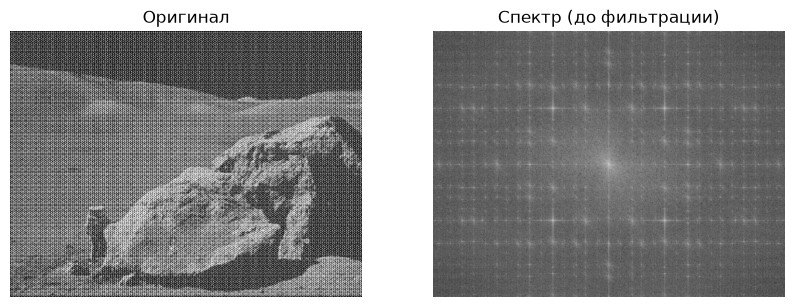

In [22]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
rows, cols = img.shape

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]))

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap='gray'); ax[0].set_title('Оригинал'); ax[0].axis('off')
ax[1].imshow(magnitude_spectrum, cmap='gray'); ax[1].set_title('Спектр (до фильтрации)'); ax[1].axis('off')
plt.show()

## 1) Высокочастотная фильтрация на основе ядра Гаусса

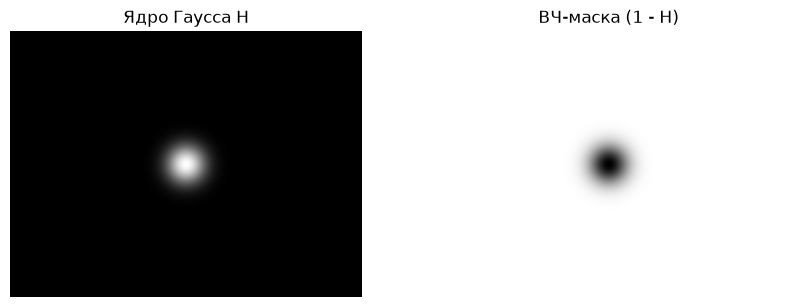

In [23]:
sigma = 30
x, y = np.meshgrid(np.arange(cols), np.arange(rows))
H = np.exp(-((x - cols//2)**2 + (y - rows//2)**2) / (2 * sigma**2))

mask_hp = 1 - H

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(H, cmap='gray'); ax[0].set_title('Ядро Гаусса H'); ax[0].axis('off')
ax[1].imshow(mask_hp, cmap='gray'); ax[1].set_title('ВЧ-маска (1 - H)'); ax[1].axis('off')
plt.show()

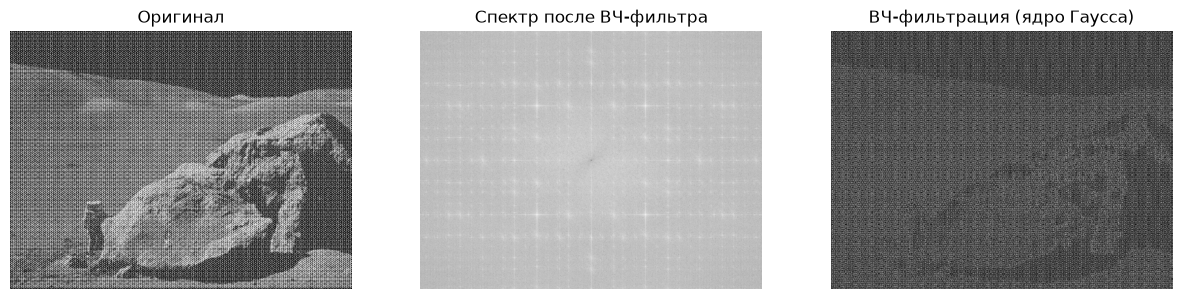

In [24]:
dft_shift_hp = dft_shift * mask_hp[:, :, np.newaxis]

f_ishift = np.fft.ifftshift(dft_shift_hp)
img_back = cv.idft(f_ishift)
img_hp = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

mag_hp = 20*np.log(cv.magnitude(dft_shift_hp[:,:,0], dft_shift_hp[:,:,1]) + 1e-6)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap='gray'); ax[0].set_title('Оригинал'); ax[0].axis('off')
ax[1].imshow(mag_hp, cmap='gray'); ax[1].set_title('Спектр после ВЧ-фильтра'); ax[1].axis('off')
ax[2].imshow(img_hp, cmap='gray'); ax[2].set_title('ВЧ-фильтрация (ядро Гаусса)'); ax[2].axis('off')
plt.show()

## 2) Вычисление свёртки с помощью преобразования Фурье

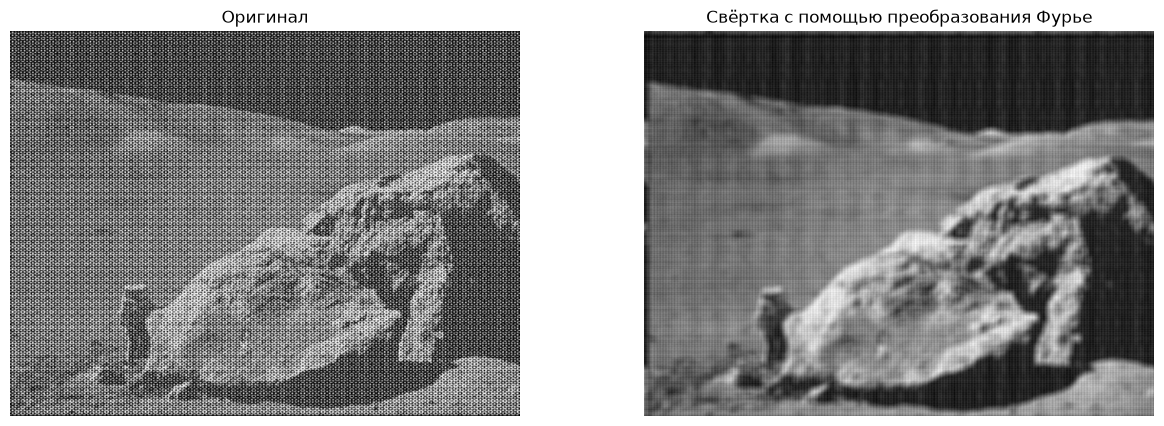

In [25]:
kernel = np.ones((11, 11), np.float32) / 121

F = np.fft.fft2(img,    s=(rows, cols))
H = np.fft.fft2(kernel, s=(rows, cols))

G = F * H

img_conv = np.real(np.fft.ifft2(G))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].imshow(img, cmap='gray'); ax[0].set_title('Оригинал'); ax[0].axis('off')
ax[1].imshow(img_conv, cmap='gray'); ax[1].set_title('Свёртка с помощью преобразования Фурье'); ax[1].axis('off')
plt.show()

## 3) Удаление периодического шума с помощью преобразования Фурье

Найдено пиков шума: 935


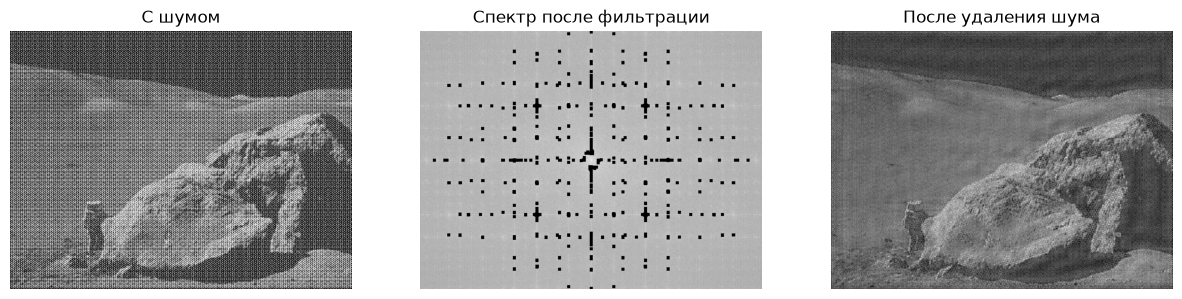

In [26]:
magnitude = cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1])
cy, cx = rows // 2, cols // 2

mag_search = magnitude.copy()
mag_search[cy-15:cy+15, cx-15:cx+15] = 0

threshold = np.percentile(mag_search, 99.8)
peaks = np.argwhere(mag_search > threshold)
print(f'Найдено пиков шума: {len(peaks)}')

dft_shift_clean = dft_shift.copy()
r_p = 3  

for py, px in peaks:
    dft_shift_clean[max(0, py-r_p):py+r_p+1, max(0, px-r_p):px+r_p+1, :] = 0
    sy, sx = 2*cy - py, 2*cx - px
    if 0 <= sy < rows and 0 <= sx < cols:
        dft_shift_clean[max(0, sy-r_p):sy+r_p+1, max(0, sx-r_p):sx+r_p+1, :] = 0

f_ishift = np.fft.ifftshift(dft_shift_clean)
img_back = cv.idft(f_ishift)
img_denoised = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

mag_denoised = 20*np.log(cv.magnitude(dft_shift_clean[:,:,0], dft_shift_clean[:,:,1]) + 1e-6)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap='gray'); ax[0].set_title('С шумом'); ax[0].axis('off')
ax[1].imshow(mag_denoised, cmap='gray'); ax[1].set_title('Спектр после фильтрации'); ax[1].axis('off')
ax[2].imshow(img_denoised, cmap='gray'); ax[2].set_title('После удаления шума'); ax[2].axis('off')
plt.show()